In [1]:
import pandas as pd

df = pd.read_csv("../data/raw/cs-training.csv")

df.head()

,Unnamed: 0,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
0,1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
1,2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
2,3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
3,4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
4,5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [2]:
df.shape

(150000, 12)

In [3]:
df.isnull().sum()

Unnamed: 0                                  0
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

In [4]:
df["SeriousDlqin2yrs"].value_counts()

SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

In [5]:
df = df.drop(columns=["Unnamed: 0"])

df["MonthlyIncome"] = df["MonthlyIncome"].fillna(
    df["MonthlyIncome"].median()
)

df["NumberOfDependents"] = df["NumberOfDependents"].fillna(
    df["NumberOfDependents"].median()
)

df.isnull().sum()

SeriousDlqin2yrs                        0
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64

In [6]:
df.to_csv(
    "../data/processed/credit_risk_clean.csv",
    index=False
)

print("Cleaned dataset saved successfully")

Cleaned dataset saved successfully


In [7]:
df.duplicated().sum()

np.int64(767)

In [8]:
df.describe()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
count,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000,1.500000e+05,150000.000000,150000.000000,150000.000000,150000.000000,150000.000000
mean,0.066840,6.048438,52.295207,0.421033,353.005076,6.418455e+03,8.452760,0.265973,1.018240,0.240387,0.737413
std,0.249746,249.755371,14.771866,4.192781,2037.818523,1.289040e+04,5.145951,4.169304,1.129771,4.155179,1.107021
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.029867,41.000000,0.000000,0.175074,3.903000e+03,5.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.154181,52.000000,0.000000,0.366508,5.400000e+03,8.000000,0.000000,1.000000,0.000000,0.000000
75%,0.000000,0.559046,63.000000,0.000000,0.868254,7.400000e+03,11.000000,0.000000,2.000000,0.000000,1.000000
max,1.000000,50708.000000,109.000000,98.000000,329664.000000,3.008750e+06,58.000000,98.000000,54.000000,98.000000,20.000000


In [9]:
df[df["age"] <= 0].shape

(1, 11)

In [10]:
df = df[df["age"] > 0].copy()

print(df.shape)

(149999, 11)


In [11]:
df[df["age"] <= 0].shape

(0, 11)

In [12]:
df[df["MonthlyIncome"] < 0].shape

(0, 11)

In [13]:
df[df["NumberOfDependents"] < 0].shape

(0, 11)

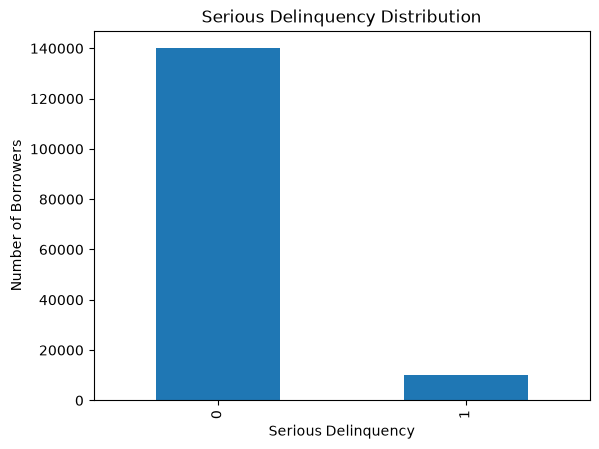

In [14]:
import matplotlib.pyplot as plt

df["SeriousDlqin2yrs"].value_counts().plot(
    kind="bar",
    title="Serious Delinquency Distribution"
)

plt.xlabel("Serious Delinquency")
plt.ylabel("Number of Borrowers")
plt.show()

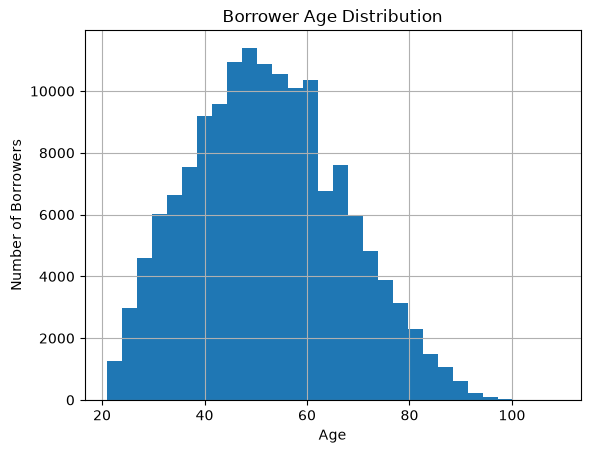

In [15]:
df["age"].hist(bins=30)

plt.title("Borrower Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Borrowers")
plt.show()

In [16]:
df["TotalPastDue"] = (
    df["NumberOfTime30-59DaysPastDueNotWorse"]
    + df["NumberOfTime60-89DaysPastDueNotWorse"]
    + df["NumberOfTimes90DaysLate"]
)

df[["TotalPastDue", "SeriousDlqin2yrs"]].head()

,TotalPastDue,SeriousDlqin2yrs
0,2,1
1,0,0
2,2,0
3,0,0
4,1,0


In [17]:
df["HasPastDue"] = (df["TotalPastDue"] > 0).astype(int)

df["HighUtilization"] = (
    df["RevolvingUtilizationOfUnsecuredLines"] > 1
).astype(int)

df["HighDebtRatio"] = (
    df["DebtRatio"] > 1
).astype(int)

In [18]:
df[
    [
        "TotalPastDue",
        "HasPastDue",
        "HighUtilization",
        "HighDebtRatio"
    ]
].head()

,TotalPastDue,HasPastDue,HighUtilization,HighDebtRatio
0,2,1,0,0
1,0,0,0,0
2,2,1,0,0
3,0,0,0,0
4,1,1,0,0


In [19]:
df.to_csv(
    "../data/processed/credit_risk_features.csv",
    index=False
)

print("Feature dataset saved successfully")

Feature dataset saved successfully


In [20]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["SeriousDlqin2yrs"])
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape, X_test.shape)

(119999, 14) (30000, 14)


In [21]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


c:\Users\vedan\credit-risk-early-warning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [22]:
from sklearn.metrics import (
    roc_auc_score,
    classification_report,
    confusion_matrix
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

ROC-AUC: 0.8209225373786466

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.83      0.90     27995
           1       0.23      0.69      0.34      2005

    accuracy                           0.82     30000
   macro avg       0.60      0.76      0.62     30000
weighted avg       0.92      0.82      0.86     30000


Confusion Matrix:
[[23288  4707]
 [  622  1383]]


In [23]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    random_state=42
)

xgb_model.fit(X_train, y_train)

print("XGBoost model trained successfully")

XGBoost model trained successfully


In [24]:
from sklearn.metrics import roc_auc_score

logistic_prob = model.predict_proba(X_test)[:, 1]
xgb_prob = xgb_model.predict_proba(X_test)[:, 1]

logistic_auc = roc_auc_score(y_test, logistic_prob)
xgb_auc = roc_auc_score(y_test, xgb_prob)

print("Logistic Regression ROC-AUC:", logistic_auc)
print("XGBoost ROC-AUC:", xgb_auc)

Logistic Regression ROC-AUC: 0.8209225373786466
XGBoost ROC-AUC: 0.8704877206875649


In [25]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

xgb_pred = (xgb_prob >= 0.5).astype(int)

print("Classification Report:")
print(classification_report(y_test, xgb_pred))

print("Confusion Matrix:")
print(confusion_matrix(y_test, xgb_pred))

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.99      0.97     27995
           1       0.59      0.20      0.30      2005

    accuracy                           0.94     30000
   macro avg       0.77      0.59      0.63     30000
weighted avg       0.92      0.94      0.92     30000

Confusion Matrix:
[[27721   274]
 [ 1606   399]]


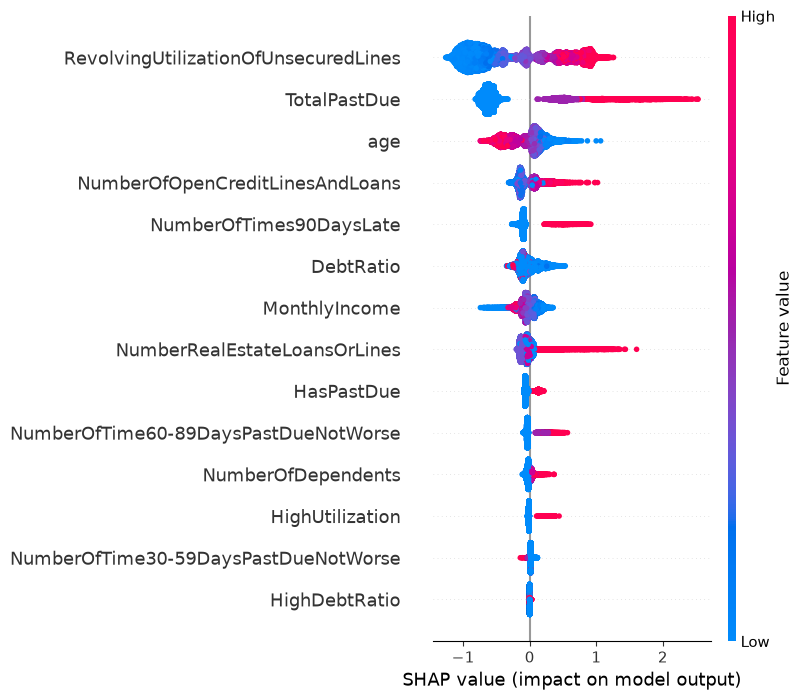

In [26]:
import shap

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test)

shap.summary_plot(shap_values, X_test)

In [27]:
df_test = X_test.copy()

df_test["ActualRisk"] = y_test
df_test["PredictedRisk"] = xgb_prob

df_test["RiskSegment"] = pd.cut(
    df_test["PredictedRisk"],
    bins=[0, 0.10, 0.30, 1.00],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

df_test["RiskSegment"].value_counts()

RiskSegment
Low       25087
Medium     3208
High       1705
Name: count, dtype: int64

In [28]:
df_test.groupby("RiskSegment", observed=True)["ActualRisk"].agg(
    Borrowers="count",
    Actual_Default_Rate="mean"
)

,Borrowers,Actual_Default_Rate
RiskSegment,,
Low,25087,0.025073
Medium,3208,0.176122
High,1705,0.475660


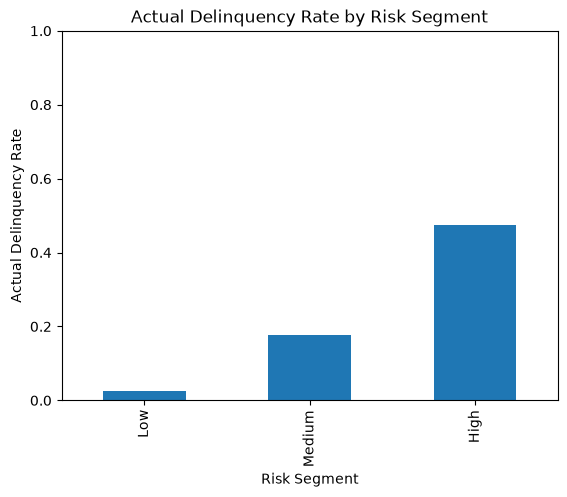

In [29]:
segment_rates = df_test.groupby(
    "RiskSegment",
    observed=True
)["ActualRisk"].mean()

segment_rates.plot(
    kind="bar",
    title="Actual Delinquency Rate by Risk Segment"
)

plt.xlabel("Risk Segment")
plt.ylabel("Actual Delinquency Rate")
plt.ylim(0, 1)
plt.show()

In [30]:
results = X_test.copy()

results["ActualRisk"] = y_test.values
results["PredictedProbability"] = xgb_prob

results["RiskSegment"] = pd.cut(
    results["PredictedProbability"],
    bins=[0, 0.10, 0.30, 1.00],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

results.to_csv(
    "../data/processed/risk_segments.csv",
    index=False
)

results.head()

,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents,TotalPastDue,HasPastDue,HighUtilization,HighDebtRatio,ActualRisk,PredictedProbability,RiskSegment
104532,0.000000,39,0,0.412698,8000.0,7,0,1,0,2.0,0,0,0,0,0,0.011829,Low
98812,0.013844,59,0,0.102674,5833.0,6,0,0,0,0.0,0,0,0,0,0,0.006334,Low
41147,0.000155,59,0,0.491822,11249.0,16,0,3,0,2.0,0,0,0,0,0,0.019668,Low
16524,0.040508,39,0,95.000000,5400.0,11,0,0,0,0.0,0,0,0,1,0,0.016132,Low
120157,0.257564,42,0,0.333333,7400.0,15,0,1,0,1.0,0,0,0,0,0,0.022962,Low


In [31]:
from sklearn.metrics import (
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score
)

logistic_pred = (logistic_prob >= 0.5).astype(int)

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "XGBoost"],
    "ROC-AUC": [
        roc_auc_score(y_test, logistic_prob),
        roc_auc_score(y_test, xgb_prob)
    ],
    "Precision": [
        precision_score(y_test, logistic_pred),
        precision_score(y_test, xgb_pred)
    ],
    "Recall": [
        recall_score(y_test, logistic_pred),
        recall_score(y_test, xgb_pred)
    ],
    "F1-Score": [
        f1_score(y_test, logistic_pred),
        f1_score(y_test, xgb_pred)
    ]
})

comparison

,Model,ROC-AUC,Precision,Recall,F1-Score
0,Logistic Regression,0.820923,0.227094,0.689776,0.341692
1,XGBoost,0.870488,0.592868,0.199002,0.297984


Final Model Comparison

XGBoost achieved a higher ROC-AUC of 0.870, compared with 0.821 for Logistic Regression. This indicates that XGBoost is better at ranking borrowers according to their credit risk.

XGBoost also achieved higher precision, meaning its high-risk predictions were more likely to be correct. However, Logistic Regression achieved higher recall, meaning it identified more borrowers who actually experienced serious delinquency.

At the current 0.5 classification threshold, Logistic Regression had the slightly higher F1-score. Overall, XGBoost is stronger for risk ranking and precision, while Logistic Regression is more suitable when identifying as many high-risk borrowers as possible is the main priority.